# Real Data -- Containment Split

Same real-data fit as `RealData_Studies.ipynb` (10% unblinded Run 2, 2.36e19 POT), but for the containment-split (contained/exiting) simultaneous fit. Reads from the `RealData_Containment` output directory.

**Likelihood:** `BarlowLLH` (not `PoissonLLH`), matching the combined-sample real-data config -- accounts for finite MC statistics, appropriate now that this is genuine data rather than Asimov/fake data.

**Known gap, not introduced here:** `dataSetListConfig_RealData.yaml` does not define `ICARUS_NuMI_1muNp0pi_cosmics`/`_cosmics_sideband` (commented out), while the containment fitSampleSet's selection/sideband samples reference them. This mismatch already exists identically in the combined-sample config (`fitSamples_reco_dpT.yaml`), so it's not something the containment split changes -- worth resolving at some point, but out of scope here.

**Binning:** truth binning is the medulla-optimized *combined* dpT binning (`binning_true_dpT.txt`, 6 finite + 1 overflow = 7 bins, shared across all 4 samples). Reco binning is per-channel: contained samples use `binning_reco_dpT_contained.txt` (20 finite + 1 overflow = 21 rows), exiting samples use `binning_reco_dpT_exiting.txt` (10 finite + 1 overflow = 11 rows).

**`cov_bin_range` -- carried over from the Asimov containment closure test (verified there, NOT yet re-verified for this run).** Block boundaries in the full 64x64 matrix are at 0, 21, 32, 53, 64 (with-overflow widths); each slice used for chi2 stops one row short of its block boundary to match the category histograms: selection_contained (0,20), selection_exiting (21,31), sideband_contained (32,52), sideband_exiting (53,63). Re-check against this run's own `covarianceMatrix_TH2D` axis labels before trusting the per-sample chi2 breakdown.

**Not included here:** the original `RealData_Studies.ipynb` has additional cells (19-27) doing bespoke mirror-dial systematic studies (VecFFCCQEshape, DecayAngMEC, Theta_Delta2Npi grid fits and LLH scans) -- specialized real-data-only diagnostics, not reusable template content. Not ported; those would need their own containment-specific adaptation if needed later.

In [17]:
try:
    from src.save_fig import save_fig
except ImportError:
    import sys, os
    sys.path.append(os.path.abspath('..'))
    from src.save_fig import save_fig

import sys
import os
sys.path.append(os.path.abspath(".."))
from src.plot_scatter import plot_scatter
from src.plot_manual_cross_section import overlay_manual_cross_section
from src.plot_fit_constraints import plot_fit_constraints
from src.plot_gundam_stacked import plot_gundam_stacked
from src.plot_GENIE_NUISANCE import overlay_genie_nuisance_xsec
from src.plot_matrices import plot_both_matrices

## Selection - Contained

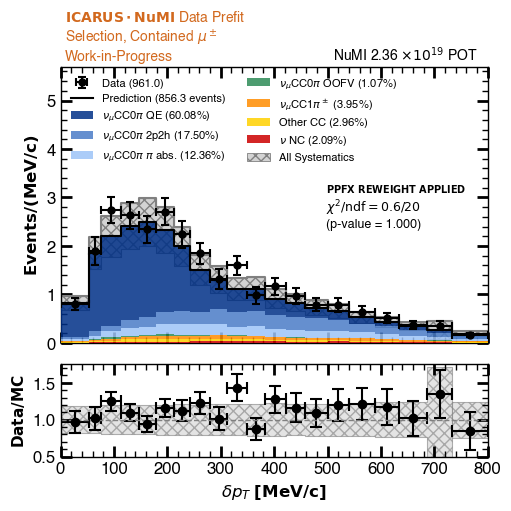

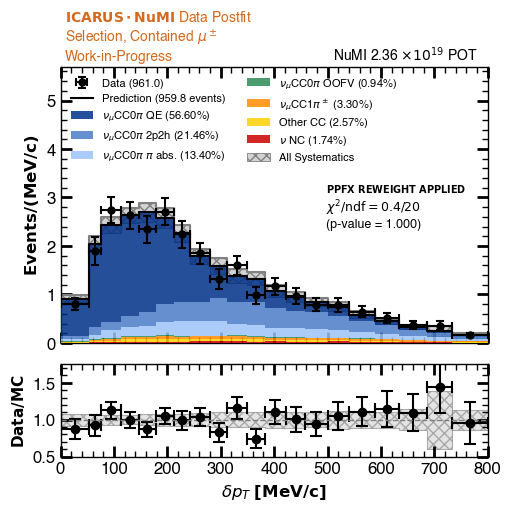

In [18]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/prefit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='selection_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # 20 finite (binning_reco_dpT_contained.txt) + 1 overflow bin. Block boundaries carried over from Asimov containment closure -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/RealData_Containment/Prefits', save_name='prefit_dpT_selection_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/postfit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='selection_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(0, 20),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dpT/RealData_Containment/Postfits', save_name='postfit_dpT_selection_contained'
)

## Selection - Exiting

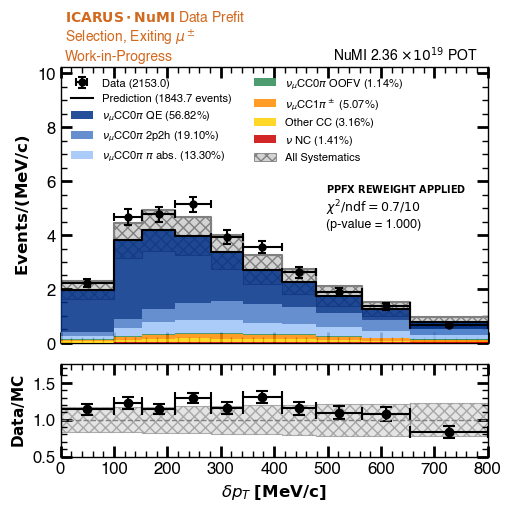

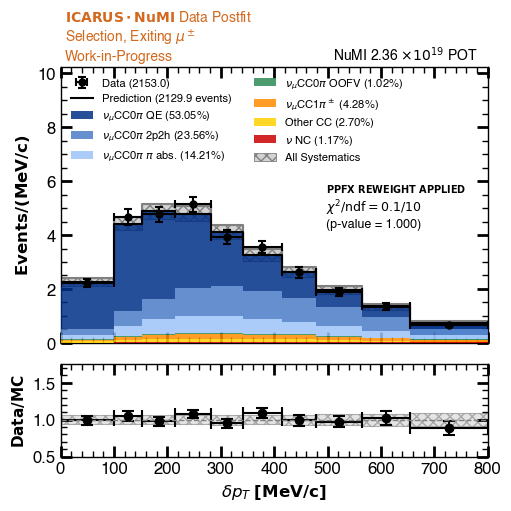

In [19]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/prefit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='selection_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # 10 finite (binning_reco_dpT_exiting.txt) + 1 overflow bin. Block boundaries carried over from Asimov containment closure -- re-verify against this run's covariance labels.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/RealData_Containment/Prefits', save_name='prefit_dpT_selection_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/postfit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='selection_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(21, 31),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Selection, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dpT/RealData_Containment/Postfits', save_name='postfit_dpT_selection_exiting'
)

## Sideband - Contained

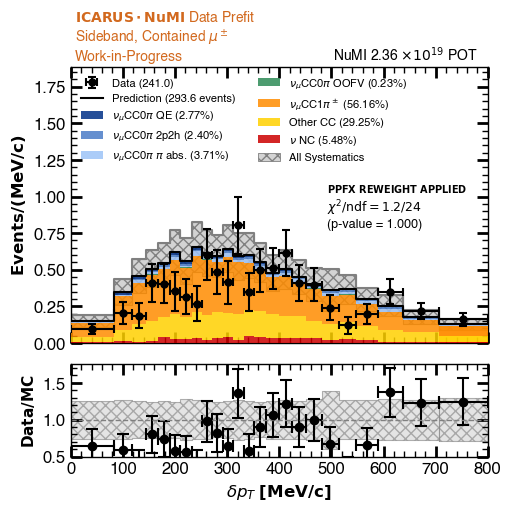

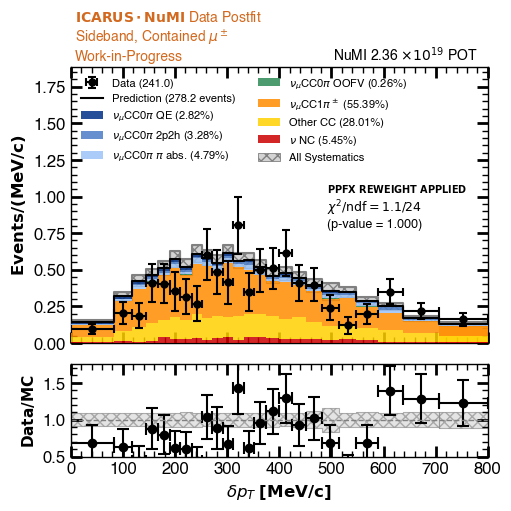

In [20]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/prefit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='sideband_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # 24 finite (binning_reco_dpT_sideband_contained.txt) + 1 overflow bin. Sideband now uses its own binning, not the selection's.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/RealData_Containment/Prefits', save_name='prefit_dpT_sideband_contained',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/postfit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='sideband_reco_dpT_contained',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(32, 56),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Contained $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dpT/RealData_Containment/Postfits', save_name='postfit_dpT_sideband_contained'
)

## Sideband - Exiting

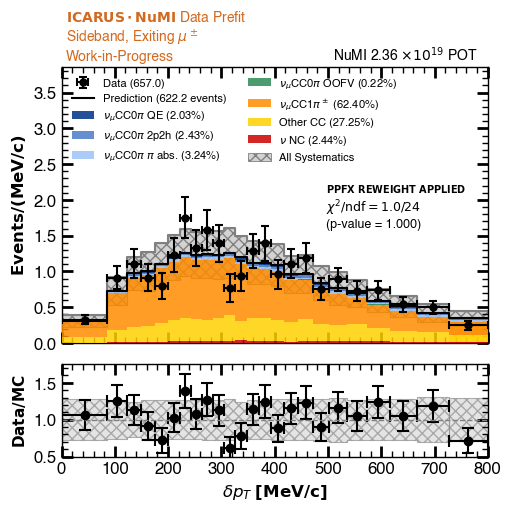

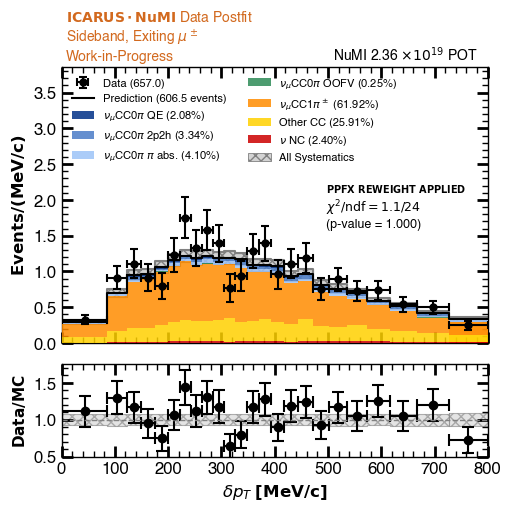

In [21]:
# Pre-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/prefit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='sideband_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # 24 finite (binning_reco_dpT_sideband_exiting.txt) + 1 overflow bin. Sideband now uses its own binning, not the selection's.
    fit_type='pre-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Prefit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    save_dir=r'../Plots/dpT/RealData_Containment/Prefits', save_name='prefit_dpT_sideband_exiting',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
)

# Post-fit plot
fig, axes, chi2_info = plot_gundam_stacked(
    postfit_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/postfit_real_containment_dpT.root',
    fitterengine_file_path='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    sample_name='sideband_reco_dpT_exiting',
    is_data=True,
    variable_name='reco_dpT_lp',
    cov_bin_range=(57, 81),  # see note above
    fit_type='post-fit',
    xlabel=r'$\delta p_T$ $\mathbf{[MeV/c]}$',
    title=r'$\bf{ICARUS \cdot NuMI}$ Data Postfit' + '\n' + 'Sideband, Exiting $\mu^\pm$' + '\n' + 'Work-in-Progress',
    pot=r'NuMI 2.36 $\times 10^{19}$ POT',
    save_dir=r'../Plots/dpT/RealData_Containment/Postfits', save_name='postfit_dpT_sideband_exiting'
)

## Cross-Section Extraction

From `real_containment_XSec_dpT.root`. Truth-level, 7 truth bins -- unchanged by the reco-level containment split.

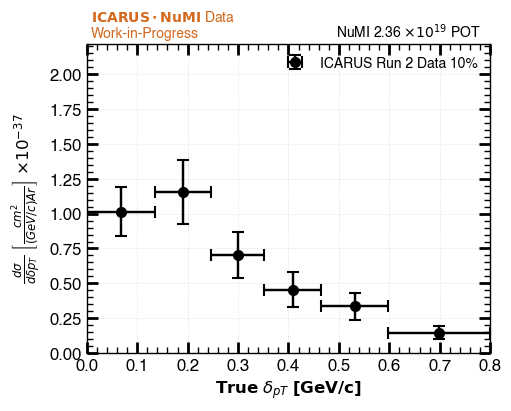

In [22]:
fig_xs, ax_xs, xsec_extracted_raw, xsec_extracted_errors_raw = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/XSection/dpT/RealData_Containment/real_containment_XSec_dpT.root',
        is_cross_section = True,
        hist_path="calcXsec/histograms/True_dpT_XS_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel=r'$\frac{d\sigma}{d\delta p_T}$ $\left[\frac{cm^2}{(GeV/c)Ar}\right]$ $\times 10^{-37}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label="ICARUS Run 2 Data 10%",
        pot=r'NuMI 2.36 $\times 10^{19}$ POT',
        scaling_power_of_10=1e40
)
save_fig(fig_xs, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS')


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.694570e-01
  0.1350 – 0.2460           1.048901e+00
  0.2460 – 0.3520           5.364335e-01
  0.3520 – 0.4650           4.182125e-01
  0.4650 – 0.5980           3.101830e-01
  0.5980 – 0.8000           1.838598e-01

χ² / Ndof = 2.8 / 6 = 0.469
p-value = 0.831


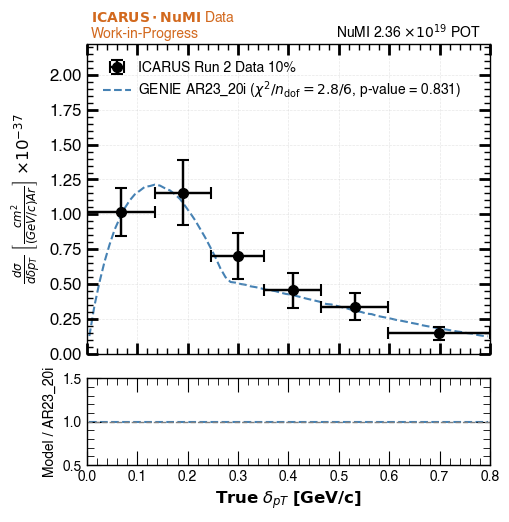

In [23]:
# Overlay GENIE with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE/fhc_Nu-14",
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'GENIE AR23_20i',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wGENIE')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           8.931566e-01
  0.1350 – 0.2460           1.114741e+00
  0.2460 – 0.3520           6.134655e-01
  0.3520 – 0.4650           4.868741e-01
  0.4650 – 0.5980           3.577055e-01
  0.5980 – 0.8000           2.072019e-01

χ² / Ndof = 2.8 / 6 = 0.470
p-value = 0.831


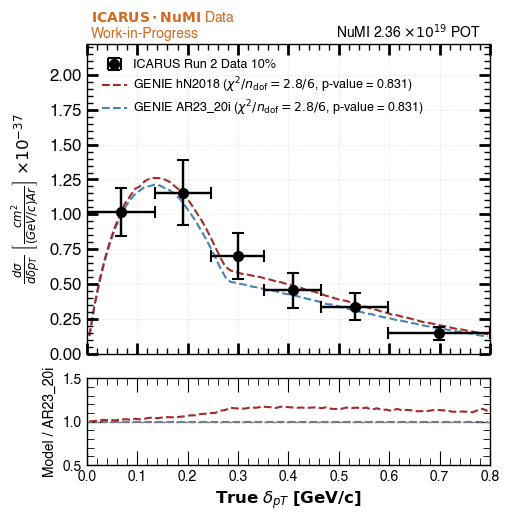

In [24]:
# Overlay GENIE hN2018 with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_hN2018/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'GENIE hN2018',
    color               = 'brown',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wGENIE_hN2018')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           9.953588e-01
  0.1350 – 0.2460           1.169325e+00
  0.2460 – 0.3520           5.731859e-01
  0.3520 – 0.4650           4.488495e-01
  0.4650 – 0.5980           3.370147e-01
  0.5980 – 0.8000           2.019417e-01

χ² / Ndof = 2.2 / 6 = 0.369
p-value = 0.899


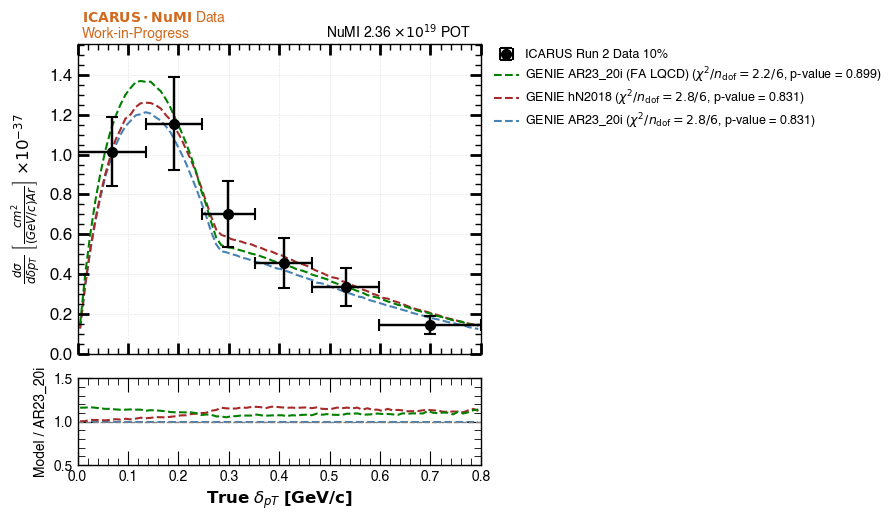

In [25]:
# Overlay GENIE LQCD with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_LQCD/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'GENIE AR23_20i (FA LQCD)',
    color               = 'green',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wGENIE_LQCD')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           1.145337e+00
  0.1350 – 0.2460           1.321915e+00
  0.2460 – 0.3520           6.241913e-01
  0.3520 – 0.4650           4.825125e-01
  0.4650 – 0.5980           3.617333e-01
  0.5980 – 0.8000           2.174629e-01

χ² / Ndof = 4.0 / 6 = 0.665
p-value = 0.678


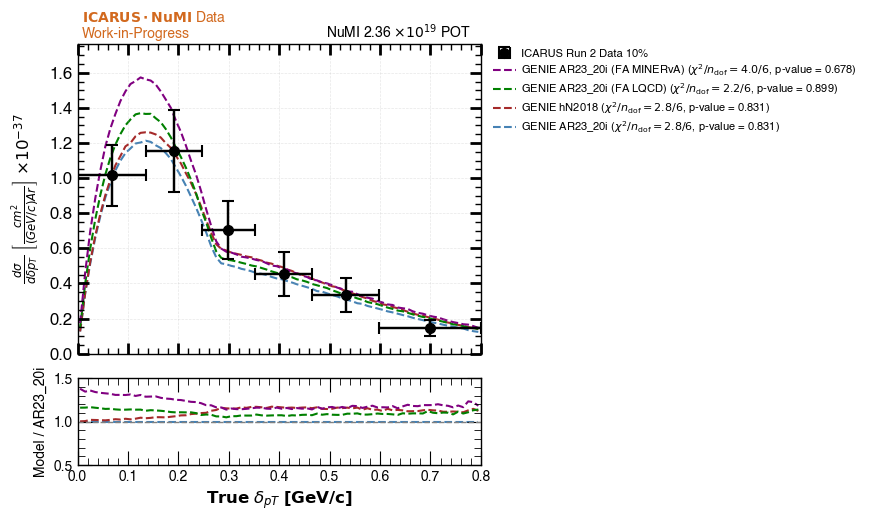

In [26]:
# Overlay GENIE MINERvA with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GENIE_MINERvA/fhc_Nu-14",
    generator_name      = 'GENIE',
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'GENIE AR23_20i (FA MINERvA)',
    color               = 'purple',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wGENIE_MINERvA')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           6.660025e-01
  0.1350 – 0.2460           1.085935e+00
  0.2460 – 0.3520           7.120627e-01
  0.3520 – 0.4650           5.680874e-01
  0.4650 – 0.5980           4.187922e-01
  0.5980 – 0.8000           2.419357e-01

χ² / Ndof = 10.3 / 6 = 1.718
p-value = 0.112


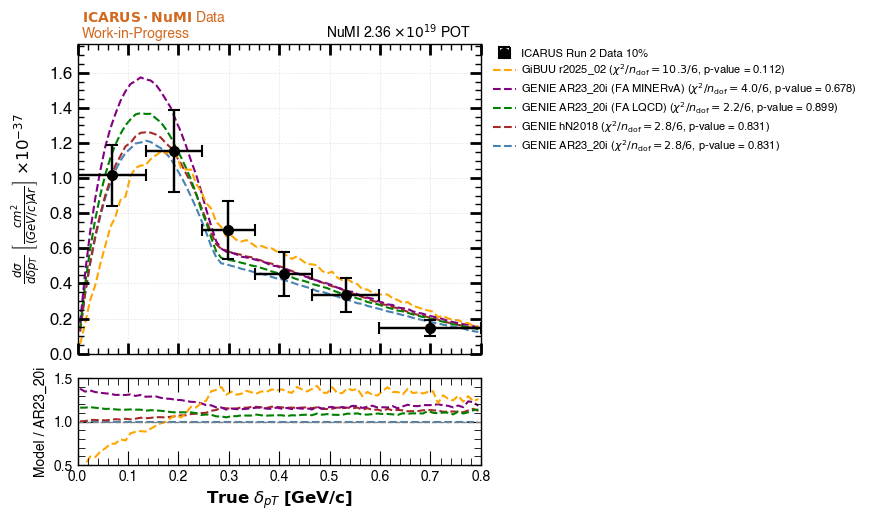

In [27]:
# Overlay GiBUU with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/GiBUU/fhc_Nu-14",
    generator_name      = 'GiBUU',
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'GiBUU r2025_02',
    color               = 'orange',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wGiBUU')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           1.148420e+00
  0.1350 – 0.2460           1.195319e+00
  0.2460 – 0.3520           4.622161e-01
  0.3520 – 0.4650           3.253492e-01
  0.4650 – 0.5980           2.326794e-01
  0.5980 – 0.8000           1.305354e-01

χ² / Ndof = 5.1 / 6 = 0.842
p-value = 0.537


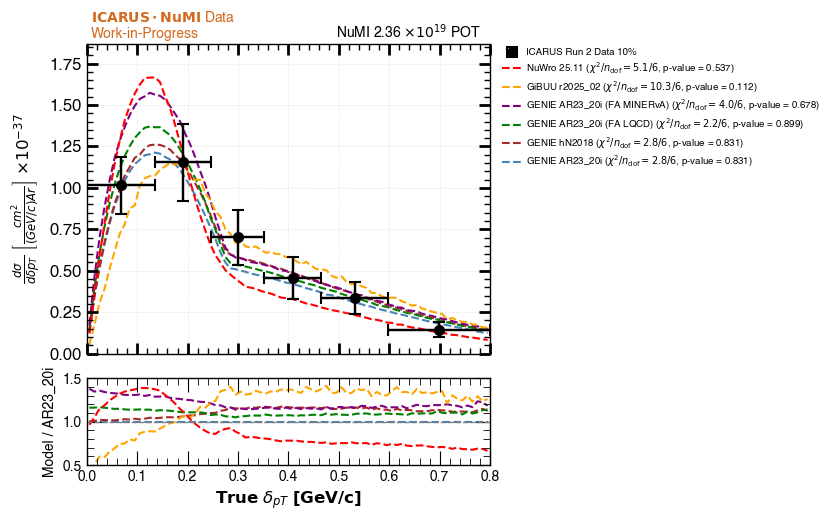

In [28]:
# Overlay NuWro with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NuWro/fhc_Nu-14",
    generator_name      = 'NuWro',
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'NuWro 25.11',
    color               = 'red',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wNuWro')
display(fig_genie)


GENIE NUISANCE Cross-Section (ICARUS_1muNp0pi_deltaPT)
Bin range                                 xsec
----------------------------------------------------------------------
  0.0000 – 0.1350           7.680762e-01
  0.1350 – 0.2460           1.118824e+00
  0.2460 – 0.3520           6.463221e-01
  0.3520 – 0.4650           4.686914e-01
  0.4650 – 0.5980           3.364536e-01
  0.5980 – 0.8000           1.923672e-01

χ² / Ndof = 3.3 / 6 = 0.546
p-value = 0.773


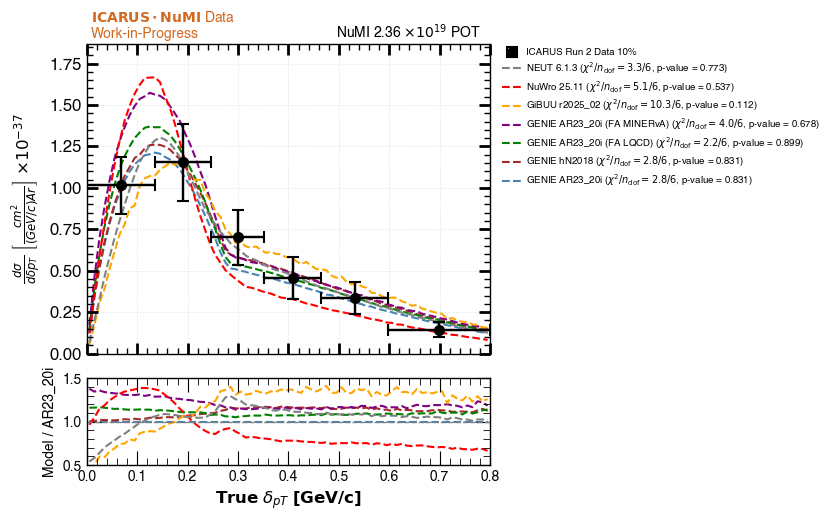

In [29]:
# Overlay NEUT with chi2
xsec_extracted = xsec_extracted_raw * 1e40
xsec_extracted_errors = xsec_extracted_errors_raw * 1e40

fig_genie, ax_genie, xsec_genie, chi2_info = overlay_genie_nuisance_xsec(
    fig_xs, ax_xs,
    nuisance_file_dir = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu14",
    nuisance_file_dir_numubar = "/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Generators/NEUT/fhc_Nu-14",
    generator_name      = 'NEUT',
    bin_edges           = [0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.80],
    nuisance_var        = 'ICARUS_1muNp0pi_deltaPT',
    scaling_power_of_10 = 1e37,
    label               = 'NEUT 6.1.3',
    color               = 'gray',
    extracted_xsec      = xsec_extracted,
    extracted_xsec_errors = xsec_extracted_errors,
    finer_binning=True,
    n_fine_bins=80,
    add_ratio=True,
    draw_extracted_ratio=False,
)
save_fig(fig_genie, r'../Plots/dpT/RealData_Containment/XSection', 'dpT_XS_wNEUT')
display(fig_genie)

## Template Parameter Post-fit Values

One set of 7 template parameters, shared across all four samples -- not split by containment.

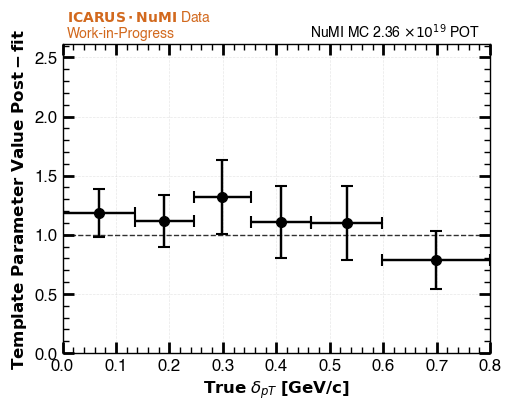

In [30]:
fig_template, ax_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
        is_cross_section = False,
        hist_path="FitterEngine/postFit/Hesse/errors/Template Parameter true_dpT_lp_genie/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{True}$ $\delta_{pT}$ $\mathbf{[GeV/c]}$',
        ylabel='$\mathbf{Template\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=[0.0, 0.135, 0.246, 0.352, 0.465, 0.598, 0.8],
        is_y_errors = True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        label=None,
        hline_nuisance=True,
        pot=r'NuMI MC 2.36 $\times 10^{19}$ POT'
)
save_fig(fig_template, r'../Plots/dpT/RealData_Containment/TemplateParameters', 'dpT')

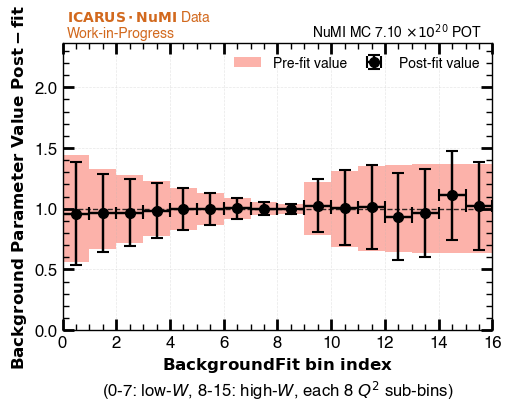

In [31]:
fig_bkg_template, ax_bkg_template, dummy, dummy2 = plot_scatter(
        filename='/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
        is_cross_section=False,
        hist_path="FitterEngine/postFit/Hesse/errors/BackgroundFit true_generator_w binbybin/values/postFitErrors_TH1D;1",
        xlabel=r'$\mathbf{BackgroundFit\ bin\ index}$' + '\n' + r'(0-7: low-$W$, 8-15: high-$W$, each 8 $Q^2$ sub-bins)',
        ylabel=r'$\mathbf{Background\ Parameter\ Value\ Post-fit}$',
        bin_edges_labels=list(range(17)),   # 17 edges -> 16 unit-width bins, matches the 16 real bins exactly
        remove_last_bin=False,               # there is no overflow bin in this scheme -- don't drop bin 15
        is_y_errors=True,
        title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
        hline_nuisance=True,
        pot=r'NuMI MC 7.10 $\times 10^{20}$ POT',
        show_prior=True,
)
save_fig(fig_bkg_template, r'../Plots/dpT/RealData_Containment/BackgroundFitParameters', 'dpT')

## Nuisance Parameter Constraints

Interaction-model, flux, and detector systematics -- one set of plots for the whole joint fit, unaffected by the reco-level split.

Number of parameters: 52


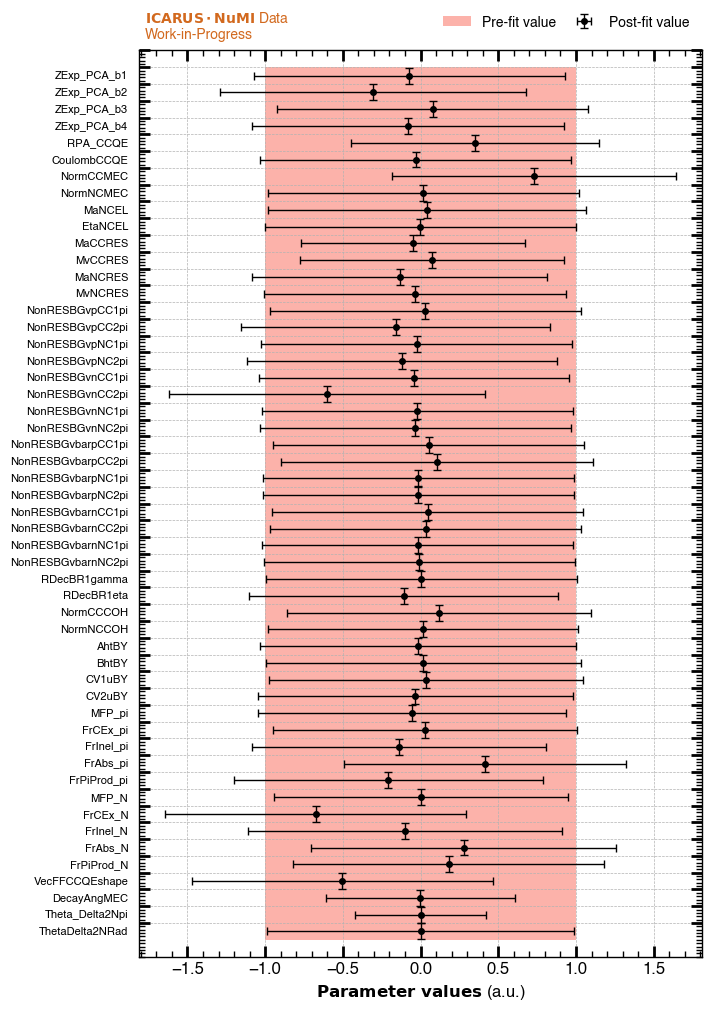

In [32]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 10),
    directory_path="FitterEngine/postFit/Hesse/errors/Cross section Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_InteractionModel')

Number of parameters: 27


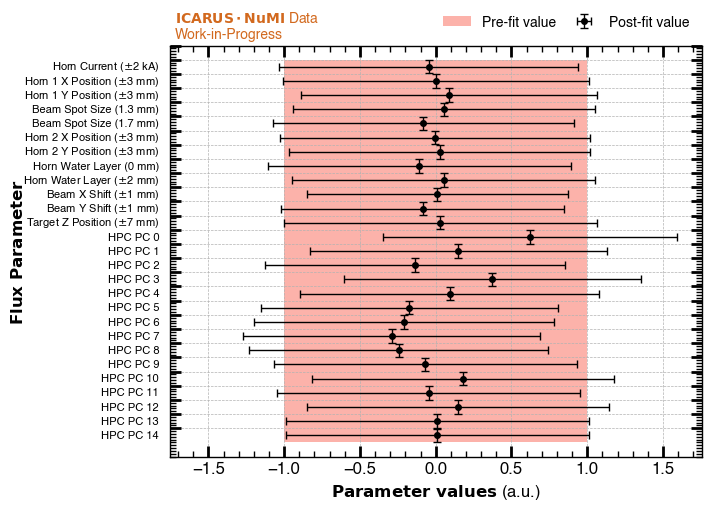

In [33]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 5),
    y_label=r'$\mathbf{Flux\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Multisigma Flux Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_Flux')

Number of parameters: 9


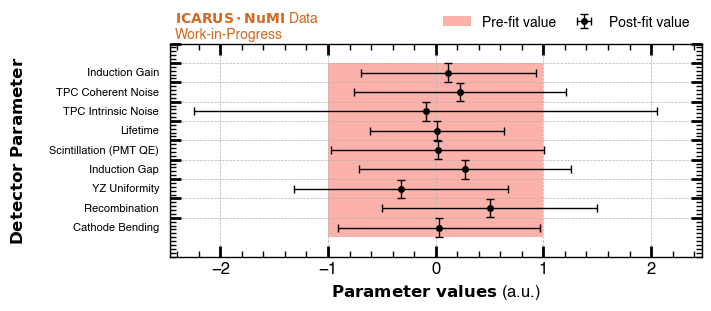

In [34]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 3),
    y_label=r'$\mathbf{Detector\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/Detector Systematics/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_Detector')

Number of parameters: 21


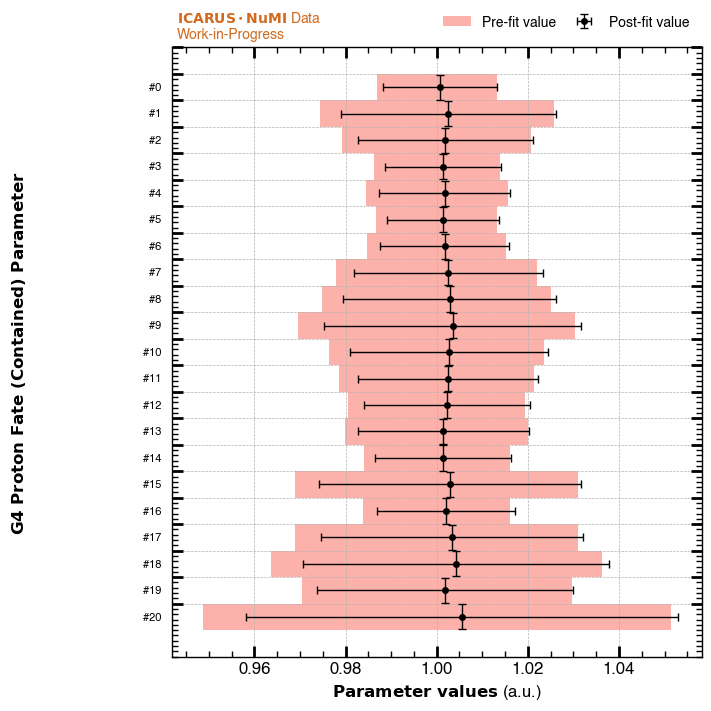

In [35]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_G4_Proton_Contained')

Number of parameters: 11


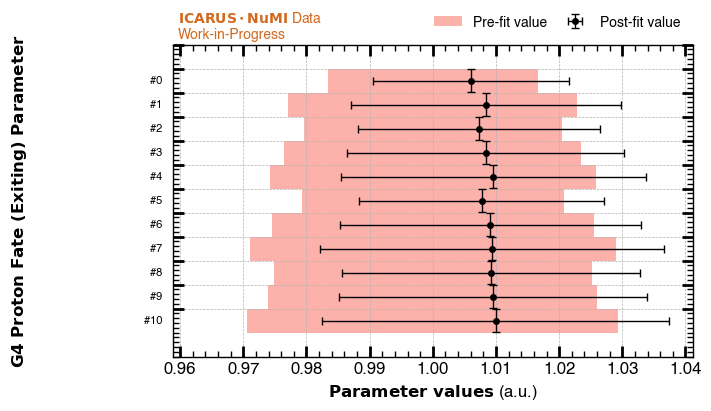

In [36]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Proton Fate (exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_G4_Proton_Exiting')

Number of parameters: 21


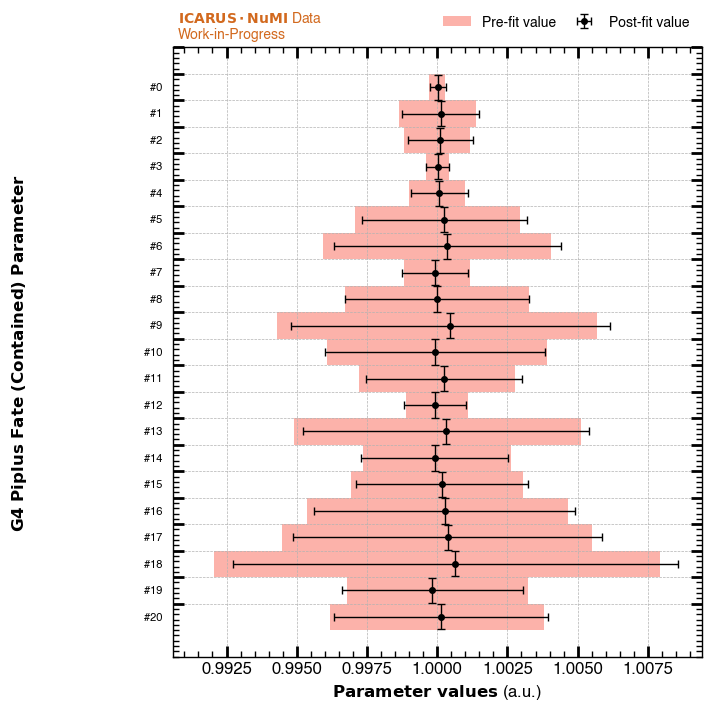

In [37]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_G4_Piplus_Contained')

Number of parameters: 11


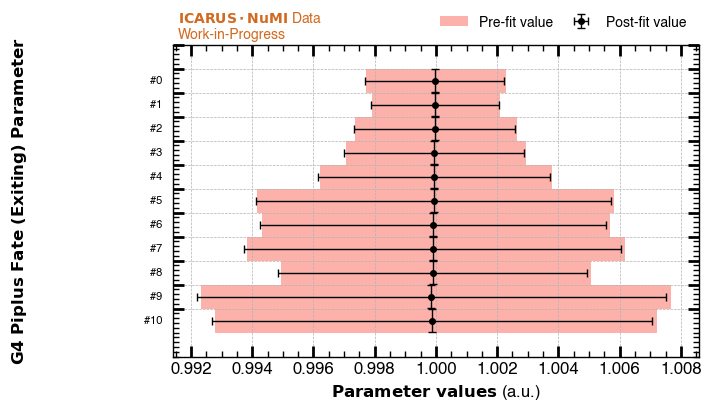

In [38]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piplus Fate (exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_G4_Piplus_Exiting')

Number of parameters: 21


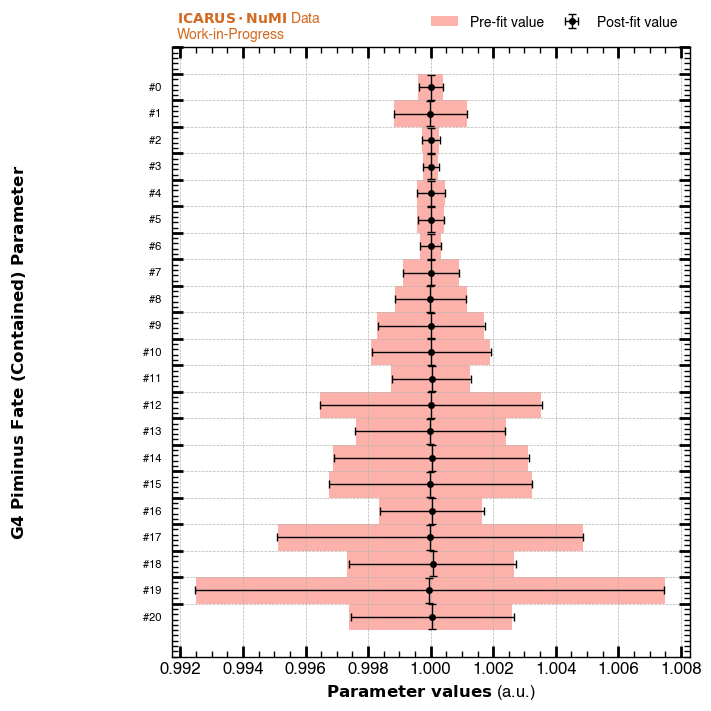

In [39]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 7),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (contained)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_G4_Piminus_Contained')

Number of parameters: 11


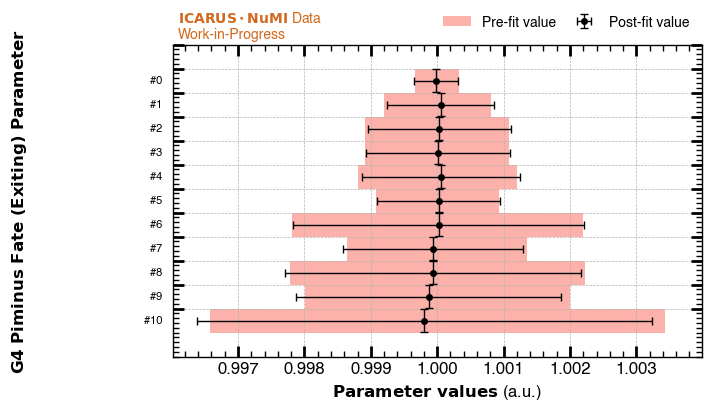

In [40]:
fig, ax = plot_fit_constraints(
    filename="/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root",
    figsize=(7, 4),
    y_label=r'$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$',
    directory_path="FitterEngine/postFit/Hesse/errors/G4 Piminus Fate (exiting)/values",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress'
)
save_fig(fig, r'../Plots/dpT/RealData_Containment/NuisanceParameters', 'dpT_G4_Piminus_Exiting')

## Covariance / Correlation Matrices

Per-systematic-block matrices -- among the nuisance parameters themselves, not among reco bins, so `bin_range` stays at its default (full block).

Full matrix size: 52×52


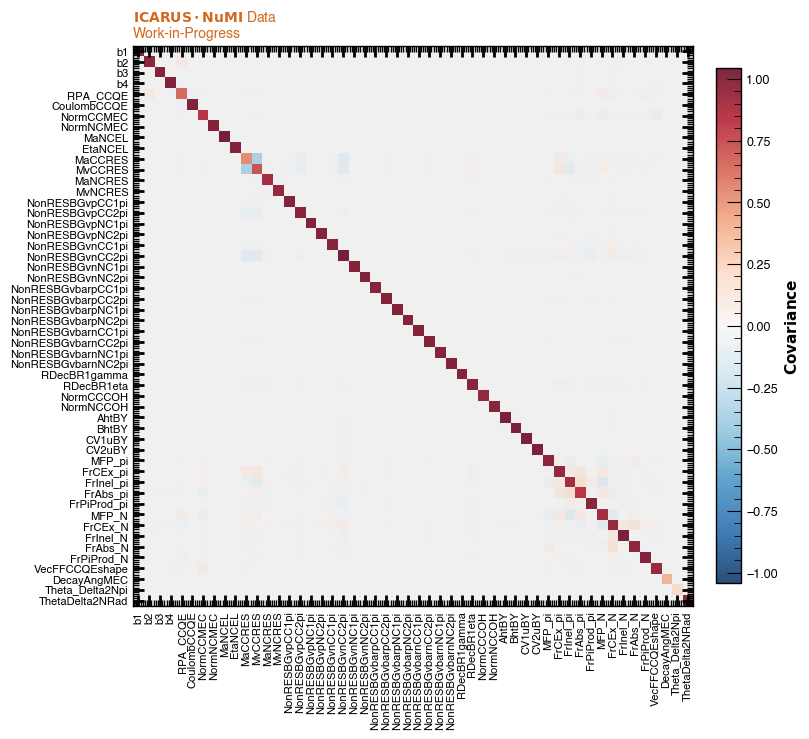

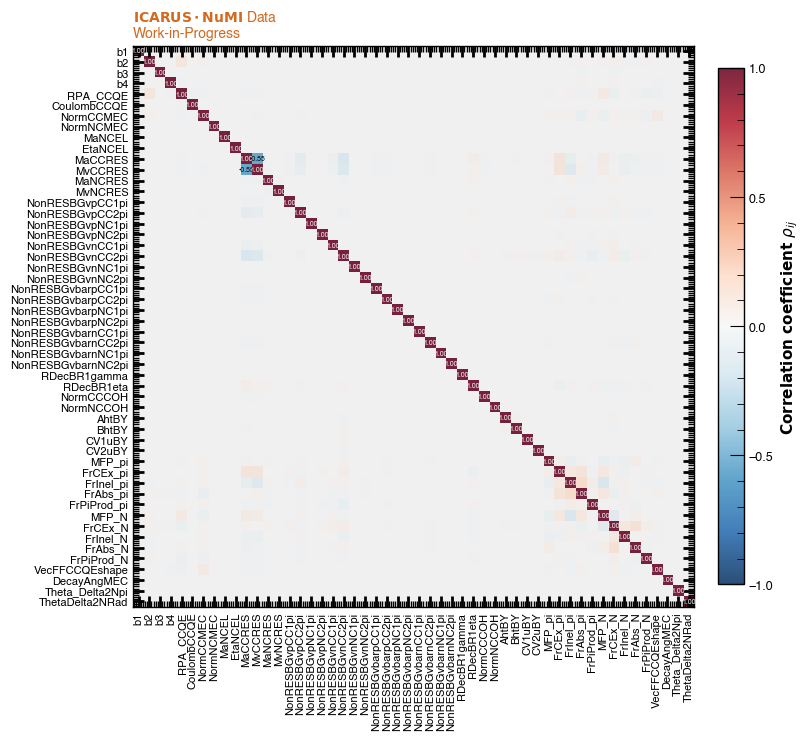

In [41]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(8, 20),
    cov_path  = f"{BASE}/Cross section Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Cross section Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'xsec_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'xsec_param_correlation')

Full matrix size: 27×27


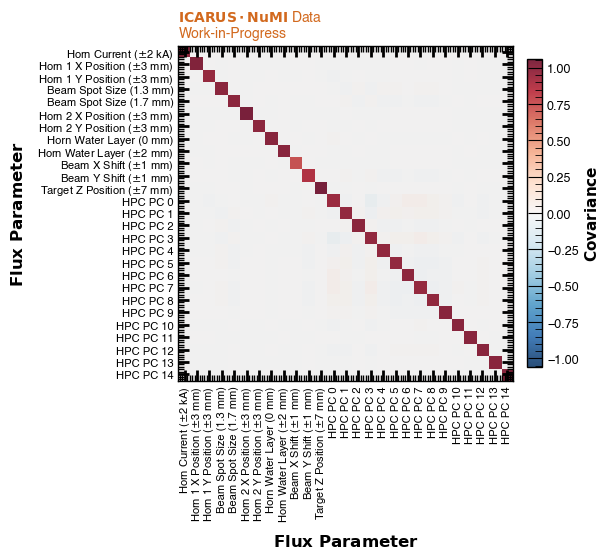

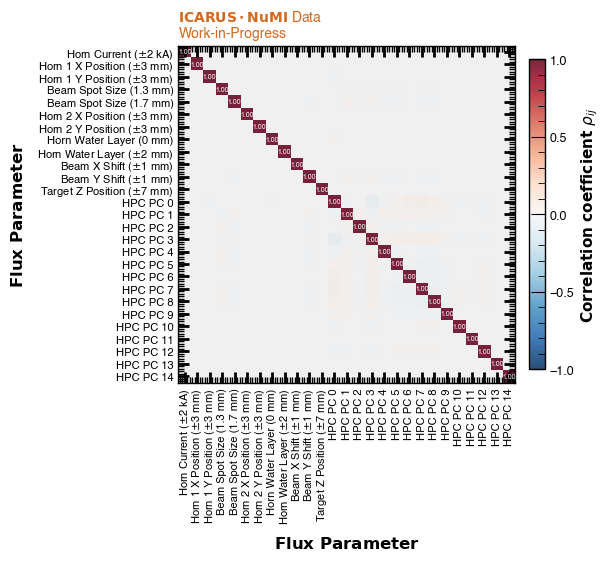

In [42]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{Flux\ Parameter}$",
    cov_path  = f"{BASE}/Multisigma Flux Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Multisigma Flux Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'flux_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'flux_param_correlation')

Full matrix size: 9×9


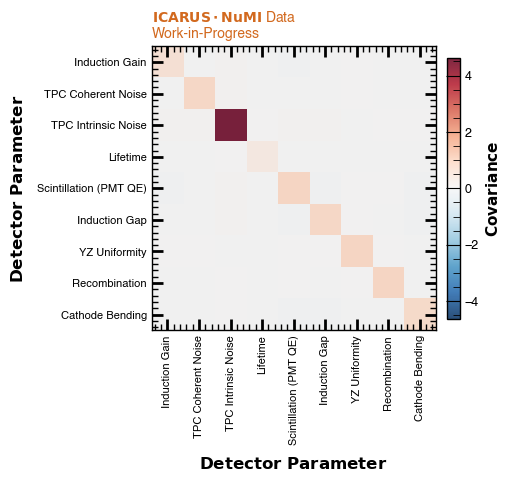

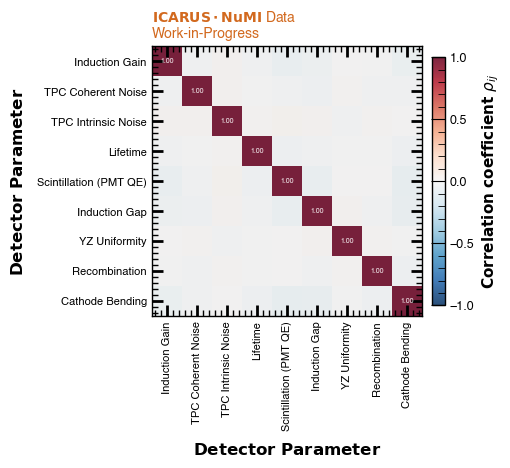

In [43]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(5, 15),
    label_name=r"$\mathbf{Detector\ Parameter}$",
    cov_path  = f"{BASE}/Detector Systematics;1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/Detector Systematics;1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'detector_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'detector_param_correlation')

Full matrix size: 21×21


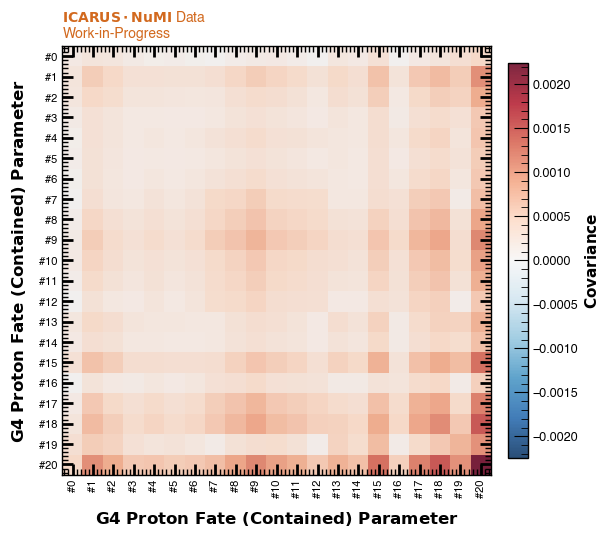

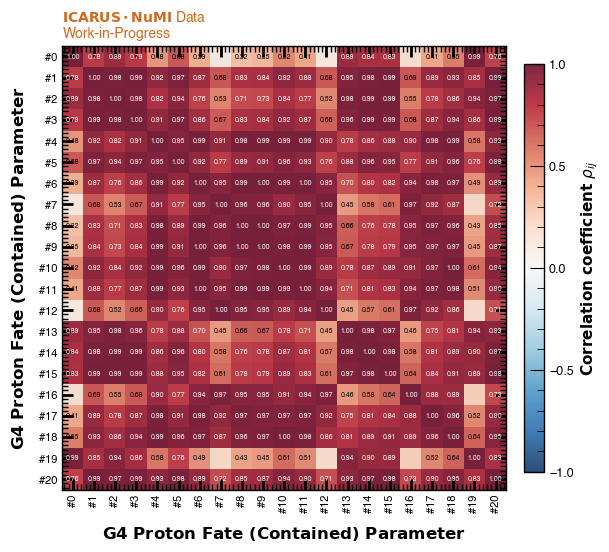

In [44]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_proton_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_proton_contained_param_correlation')

Full matrix size: 11×11


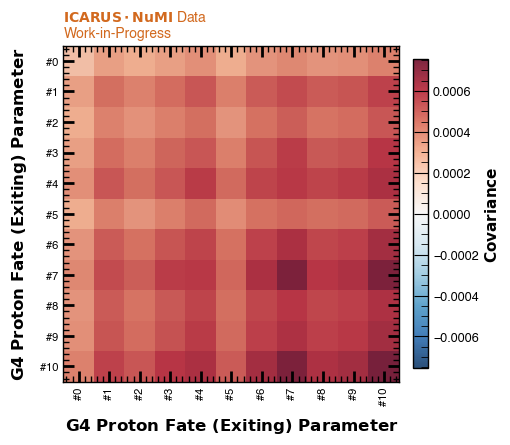

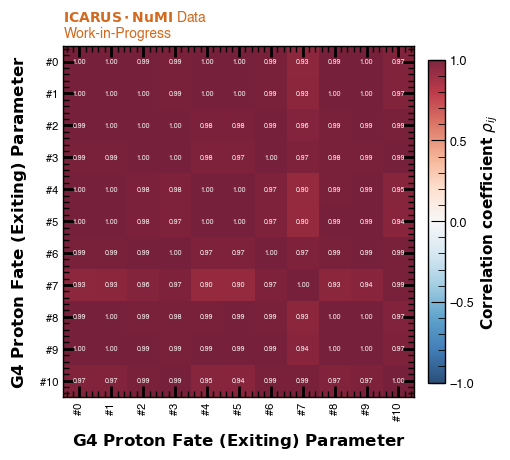

In [45]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(5, 12),
    label_name=r"$\mathbf{G4\ Proton\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Proton Fate (exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Proton Fate (exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_proton_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_proton_exiting_param_correlation')

Full matrix size: 21×21


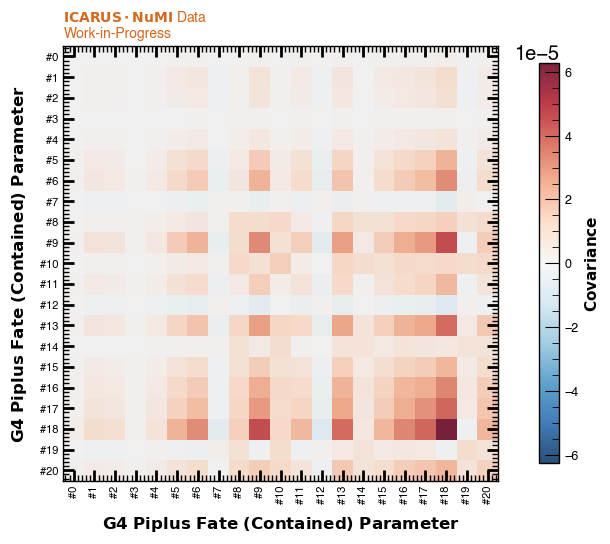

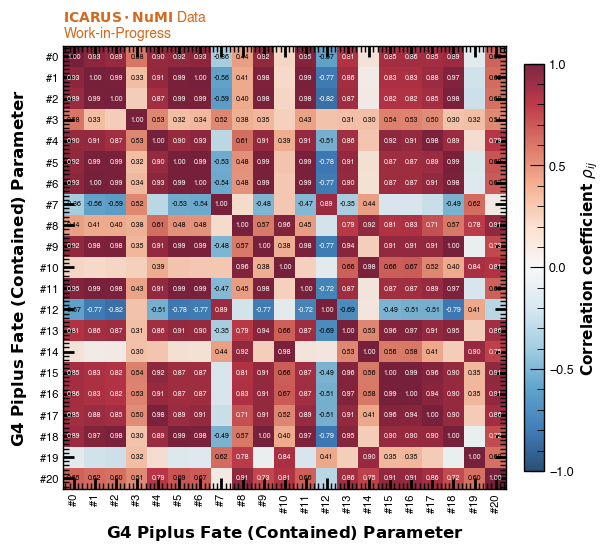

In [46]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piplus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piplus_contained_param_correlation')

Full matrix size: 11×11


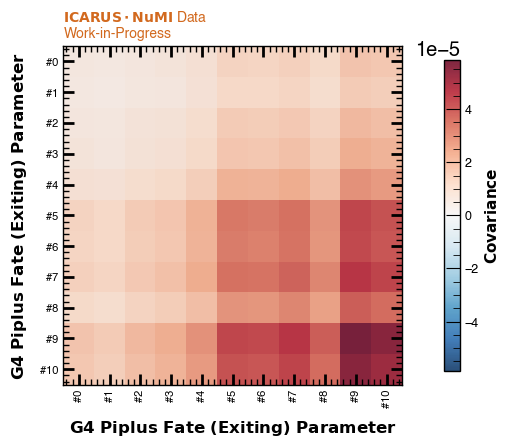

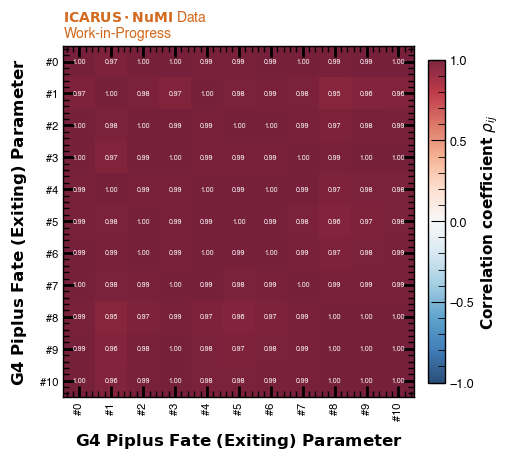

In [47]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(5, 12),
    label_name=r"$\mathbf{G4\ Piplus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piplus Fate (exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piplus Fate (exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piplus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piplus_exiting_param_correlation')

Full matrix size: 21×21


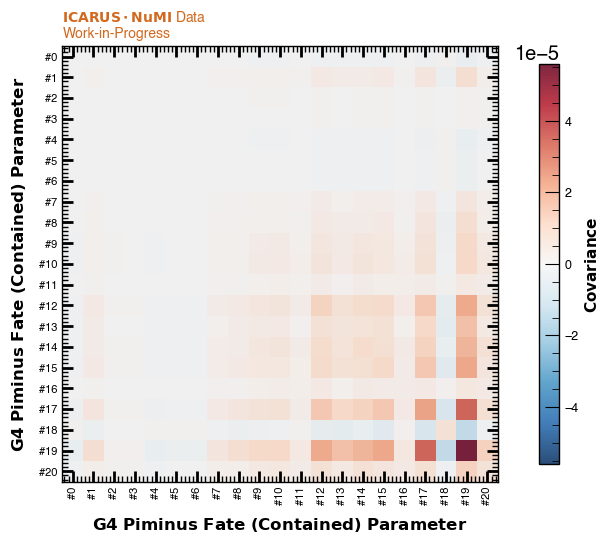

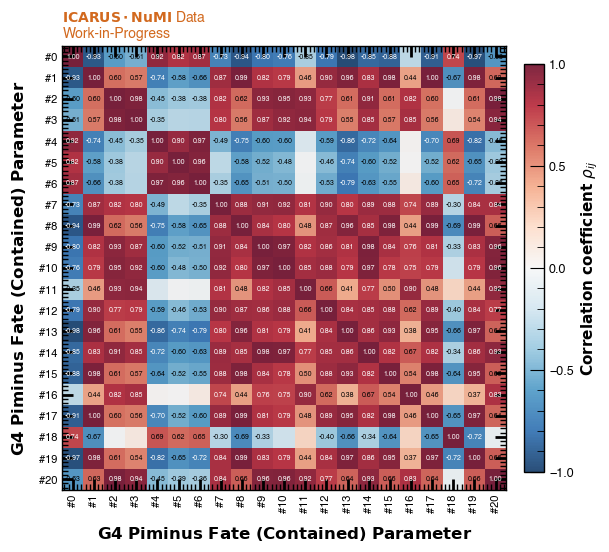

In [48]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(6, 15),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Contained)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (contained);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (contained);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piminus_contained_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piminus_contained_param_correlation')

Full matrix size: 11×11


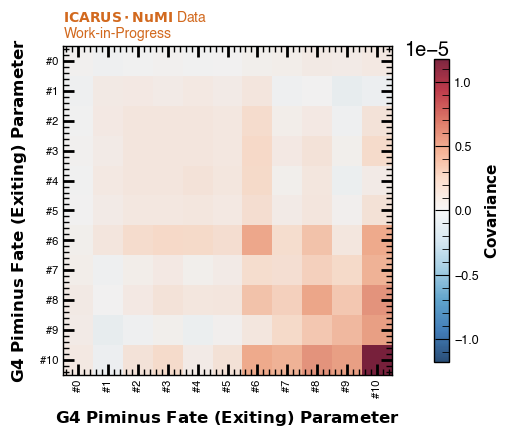

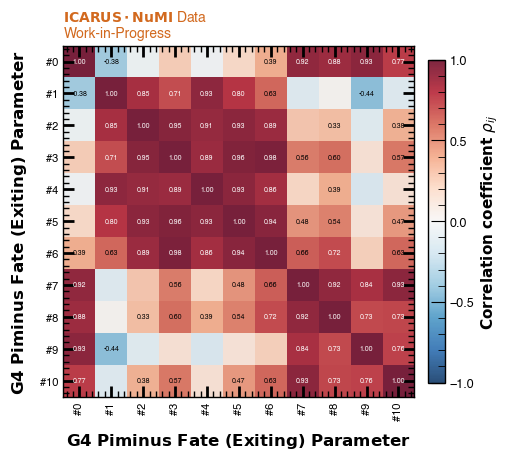

In [49]:
BASE = "FitterEngine/postFit/Hesse/errors"
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(5, 12),
    label_name=r"$\mathbf{G4\ Piminus\ Fate\ (Exiting)\ Parameter}$",
    cov_path  = f"{BASE}/G4 Piminus Fate (exiting);1/matrices/Covariance_TH2D;1",
    corr_path = f"{BASE}/G4 Piminus Fate (exiting);1/matrices/Correlation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piminus_exiting_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'g4_piminus_exiting_param_correlation')

## Full Covariance / Correlation Matrix (All Systematics + Template Parameters)

Single matrix over every free parameter in the fit -- template, background-fit, cross-section, flux, detector, and all six G4 groups -- read from the fitter's own postfit Hessian block (`FitterEngine/postFit/Hesse/hessian`), not the per-group `errors` blocks the cells above use. `annotate` is left off here since the matrix is too large (190x190) for per-cell values to be legible.

In [50]:
BASE_ALL = "FitterEngine/postFit/Hesse/hessian"
GROUP_ORDER = [
    "Template Parameter true_dpT_lp_genie",
    "Cross section Systematics",
    "Multisigma Flux Systematics",
    "Detector Systematics",
    "G4 Proton Fate (contained)",
    "G4 Proton Fate (exiting)",
    "G4 Piplus Fate (contained)",
    "G4 Piplus Fate (exiting)",
    "G4 Piminus Fate (contained)",
    "G4 Piminus Fate (exiting)",
    "BackgroundFit true_generator_w binbybin",
]
(fig_cov, ax_cov), (fig_corr, ax_corr) = plot_both_matrices(
    '/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/data/Fitter/dpT/RealData_Containment/real_containment_dpT.root',
    figsize=(30, 24),
    cov_path  = f"{BASE_ALL}/postfitCovariance_TH2D;1",
    corr_path = f"{BASE_ALL}/postfitCorrelation_TH2D;1",
    title_line1=r'$\bf{ICARUS \cdot NuMI}$ Data' + '\n' + 'Work-in-Progress',
    annotate=False,
    group_order=GROUP_ORDER,
    show_group_boundaries=True,
)
save_fig(fig_cov, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'all_param_covariance')
save_fig(fig_corr, r'/Users/rvizarreta/Library/CloudStorage/GoogleDrive-rvizarreta14@gmail.com/My Drive/🏛 PhD Repository/🚀 Research/🤖 Experiments&Projects/ICARUS/ICARUS_CC0pi_GUNDAM/gundam-icarus/Notebooks/Plots/dpT/RealData_Containment/Postfits', 'all_param_correlation')

TypeError: plot_both_matrices() got an unexpected keyword argument 'show_group_boundaries'